In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

np.random.seed(42)

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(
    "data_banknote_authentication.txt",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
display(df.head())

print("\nClass distribution:")
print(df["class"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


## Part A - Decision Tree from Scratch

In [2]:
# Select two features for decision-boundary visualization
X_2d = df[["variance", "skewness"]].values
y = df["class"].values

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train_2d.shape)
print("Testing shape:", X_test_2d.shape)

Training shape: (1097, 2)
Testing shape: (275, 2)


In [3]:
def gini_impurity(y):
    if len(y) == 0:
        return 0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def entropy(y):
    if len(y) == 0:
        return 0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))


# Test the functions
example_labels = np.array([0, 0, 1, 1])

print("Gini impurity:", gini_impurity(example_labels))
print("Entropy:", entropy(example_labels))

Gini impurity: 0.5
Entropy: 1.0


In [4]:
def best_split(X, y, criterion="gini"):
    n_samples, n_features = X.shape

    if n_samples <= 1:
        return None, None, None

    impurity_function = (
        gini_impurity if criterion == "gini" else entropy
    )

    parent_impurity = impurity_function(y)

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in range(n_features):
        thresholds = np.unique(X[:, feature])

        for threshold in thresholds[:-1]:
            left_mask = X[:, feature] <= threshold
            right_mask = ~left_mask

            if not left_mask.any() or not right_mask.any():
                continue

            y_left = y[left_mask]
            y_right = y[right_mask]

            weighted_impurity = (
                len(y_left) / n_samples * impurity_function(y_left)
                + len(y_right) / n_samples * impurity_function(y_right)
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = (
                    threshold + thresholds[np.where(thresholds == threshold)[0][0] + 1]
                ) / 2

    if best_feature is None:
        return None, None, None

    return best_feature, best_threshold, best_gain

In [12]:
class ManualDecisionTree:
    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2
    ):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def _majority_class(self, y):
        values, counts = np.unique(y, return_counts=True)
        return values[np.argmax(counts)]

    def _build_tree(self, X, y, depth):
        # Create the current node
        node = {
            "prediction": self._majority_class(y),
            "samples": len(y),
            "impurity": (
                gini_impurity(y)
                if self.criterion == "gini"
                else entropy(y)
            )
        }

        # Stopping conditions
        if (
            len(np.unique(y)) == 1
            or (
                self.max_depth is not None
                and depth >= self.max_depth
            )
            or len(y) < self.min_samples_split
        ):
            return node

        # Find the best split
        feature, threshold, gain = best_split(
            X, y, self.criterion
        )

        # Stop if no useful split is available
        if feature is None or gain <= 0:
            return node

        # Divide the samples into left and right groups
        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        # Store the split information
        node["feature"] = feature
        node["threshold"] = threshold
        node["gain"] = gain

        # Build child nodes recursively
        node["left"] = self._build_tree(
            X[left_mask],
            y[left_mask],
            depth + 1
        )

        node["right"] = self._build_tree(
            X[right_mask],
            y[right_mask],
            depth + 1
        )

        return node

    def fit(self, X, y):
        self.root = self._build_tree(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        # Leaf node: return its predicted class
        if "feature" not in node:
            return node["prediction"]

        # Follow the appropriate branch
        if x[node["feature"]] <= node["threshold"]:
            return self._predict_one(x, node["left"])

        return self._predict_one(x, node["right"])

    def predict(self, X):
        return np.array([
            self._predict_one(x, self.root)
            for x in X
        ])

In [13]:
manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=5
)

start_time = time.perf_counter()
manual_tree.fit(X_train_2d, y_train_2d)
manual_tree_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
manual_tree_predictions = manual_tree.predict(X_test_2d)
manual_tree_prediction_time = time.perf_counter() - start_time

print("Manual Decision Tree")
print("Accuracy:", accuracy_score(y_test_2d, manual_tree_predictions))
print("Precision:", precision_score(y_test_2d, manual_tree_predictions, zero_division=0))
print("Recall:", recall_score(y_test_2d, manual_tree_predictions, zero_division=0))
print("F1-score:", f1_score(y_test_2d, manual_tree_predictions, zero_division=0))
print("Training time:", manual_tree_train_time)
print("Prediction time:", manual_tree_prediction_time)

Manual Decision Tree
Accuracy: 0.9309090909090909
Precision: 0.8814814814814815
Recall: 0.9754098360655737
F1-score: 0.9260700389105059
Training time: 1.8098968999984208
Prediction time: 0.0021349999879021198


In [14]:
sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

start_time = time.perf_counter()
sklearn_tree.fit(X_train_2d, y_train_2d)
sklearn_tree_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
sklearn_tree_predictions = sklearn_tree.predict(X_test_2d)
sklearn_tree_prediction_time = time.perf_counter() - start_time

print("Scikit-learn Decision Tree")
print("Accuracy:", accuracy_score(y_test_2d, sklearn_tree_predictions))
print("Precision:", precision_score(y_test_2d, sklearn_tree_predictions, zero_division=0))
print("Recall:", recall_score(y_test_2d, sklearn_tree_predictions, zero_division=0))
print("F1-score:", f1_score(y_test_2d, sklearn_tree_predictions, zero_division=0))
print("Training time:", sklearn_tree_train_time)
print("Prediction time:", sklearn_tree_prediction_time)

print(
    "Prediction agreement:",
    np.mean(manual_tree_predictions == sklearn_tree_predictions)
)

Scikit-learn Decision Tree
Accuracy: 0.9309090909090909
Precision: 0.8814814814814815
Recall: 0.9754098360655737
F1-score: 0.9260700389105059
Training time: 0.013239500025520101
Prediction time: 0.002007699979003519
Prediction agreement: 1.0


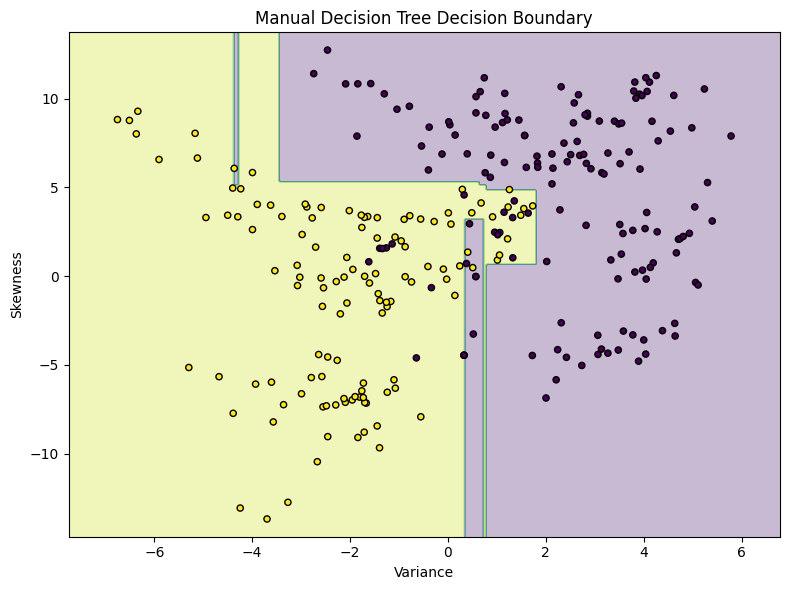

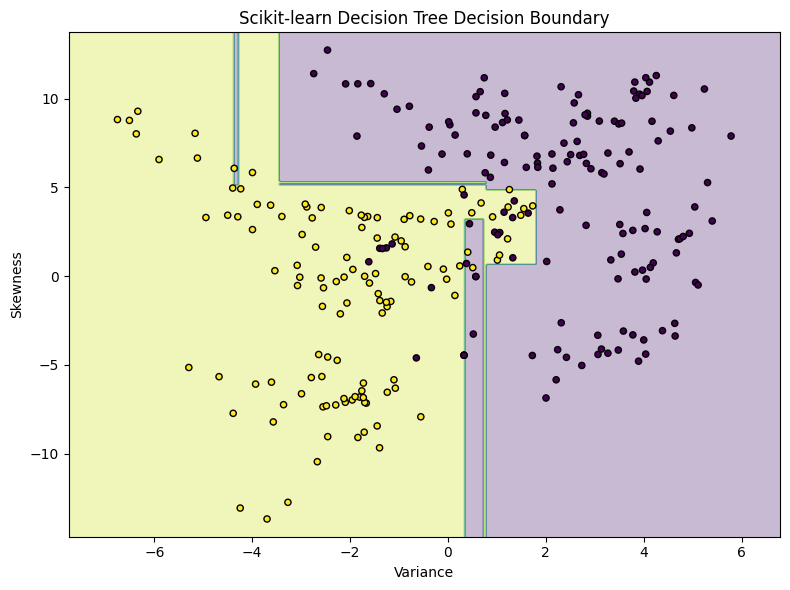

In [15]:
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, predictions, alpha=0.3)
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, edgecolors="black", s=20
    )

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.tight_layout()
    plt.show()


plot_decision_boundary(
    manual_tree, X_test_2d, y_test_2d,
    "Manual Decision Tree Decision Boundary"
)

plot_decision_boundary(
    sklearn_tree, X_test_2d, y_test_2d,
    "Scikit-learn Decision Tree Decision Boundary"
)

In [16]:
feature_names = ["variance", "skewness"]

def print_tree_rules(node, feature_names, indent=""):
    if "feature" not in node:
        print(indent + "Predict class:", node["prediction"])
        return

    feature_name = feature_names[node["feature"]]
    threshold = node["threshold"]

    print(f"{indent}IF {feature_name} <= {threshold:.4f}")
    print_tree_rules(node["left"], feature_names, indent + "  ")

    print(f"{indent}ELSE ({feature_name} > {threshold:.4f})")
    print_tree_rules(node["right"], feature_names, indent + "  ")


print_tree_rules(manual_tree.root, feature_names)

IF variance <= 0.7651
  IF skewness <= 5.1608
    IF variance <= 0.3202
      IF variance <= -0.4586
        IF skewness <= 0.0548
          Predict class: 1
        ELSE (skewness > 0.0548)
          Predict class: 1
      ELSE (variance > -0.4586)
        IF skewness <= -0.1666
          Predict class: 1
        ELSE (skewness > -0.1666)
          Predict class: 1
    ELSE (variance > 0.3202)
      IF skewness <= 3.2197
        IF variance <= 0.7406
          Predict class: 0
        ELSE (variance > 0.7406)
          Predict class: 1
      ELSE (skewness > 3.2197)
        Predict class: 1
  ELSE (skewness > 5.1608)
    IF variance <= -3.4311
      IF variance <= -4.3819
        Predict class: 1
      ELSE (variance > -4.3819)
        IF variance <= -4.2554
          Predict class: 0
        ELSE (variance > -4.2554)
          Predict class: 1
    ELSE (variance > -3.4311)
      IF skewness <= 5.3646
        IF variance <= 0.6458
          Predict class: 1
        ELSE (variance > 0.

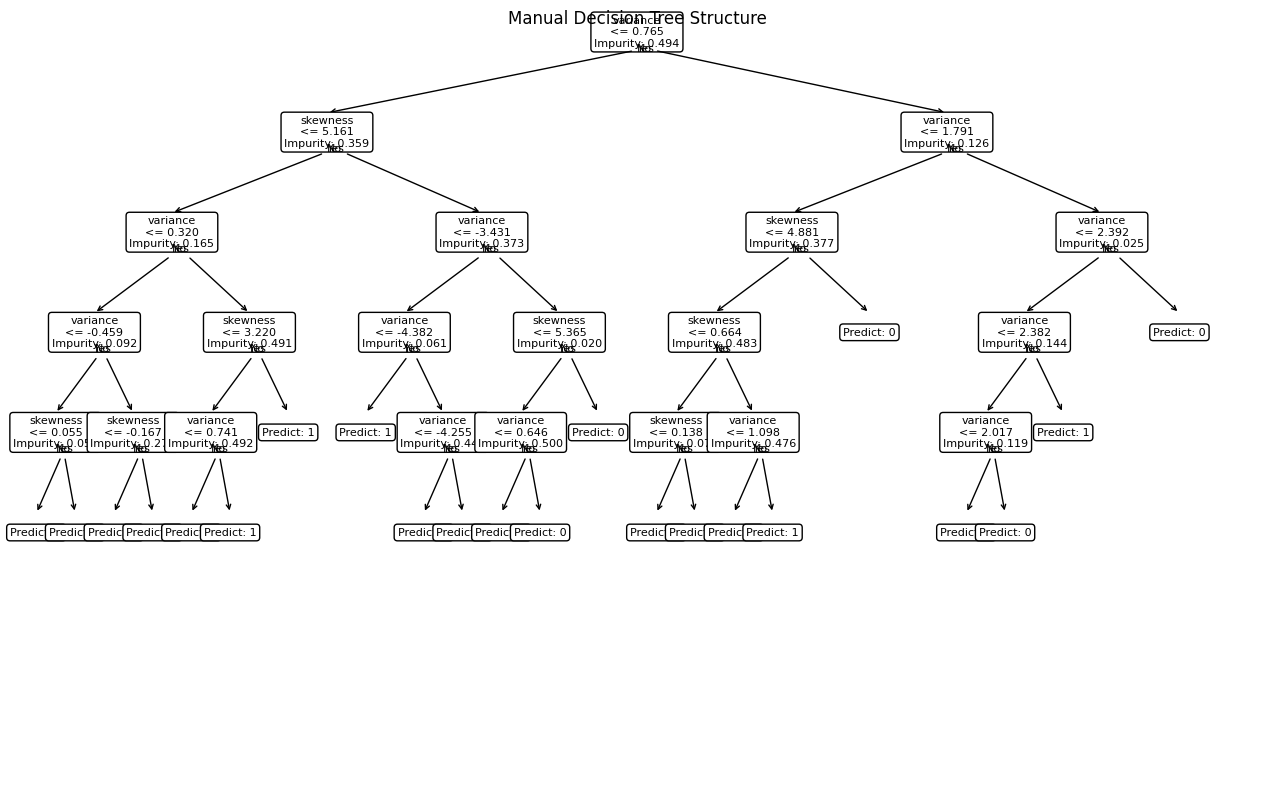

In [17]:
def draw_manual_tree(node, feature_names, ax, x=0.5, y=1.0,
                    dx=0.25, dy=0.13):
    if "feature" in node:
        label = (
            f"{feature_names[node['feature']]}\n"
            f"<= {node['threshold']:.3f}\n"
            f"Impurity: {node['impurity']:.3f}"
        )
    else:
        label = f"Predict: {node['prediction']}"

    ax.text(
        x, y, label,
        ha="center", va="center",
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="black"),
        fontsize=8,
        transform=ax.transAxes
    )

    if "feature" in node:
        children = [
            (node["left"], x - dx, "Yes"),
            (node["right"], x + dx, "No")
        ]

        for child, child_x, branch_label in children:
            child_y = y - dy

            ax.annotate(
                branch_label,
                xy=(child_x, child_y + 0.025),
                xytext=(x, y - 0.025),
                xycoords=ax.transAxes,
                textcoords=ax.transAxes,
                arrowprops=dict(arrowstyle="->"),
                fontsize=8
            )

            draw_manual_tree(
                child, feature_names, ax,
                child_x, child_y, dx / 2, dy
            )


fig, ax = plt.subplots(figsize=(16, 10))
ax.axis("off")
draw_manual_tree(manual_tree.root, feature_names, ax)
plt.title("Manual Decision Tree Structure")
plt.show()

In [18]:
tree_results = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 5, 8, None]:
        model = ManualDecisionTree(
            criterion=criterion,
            max_depth=depth
        )

        start = time.perf_counter()
        model.fit(X_train_2d, y_train_2d)
        train_time = time.perf_counter() - start

        predictions = model.predict(X_test_2d)

        tree_results.append({
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Accuracy": accuracy_score(y_test_2d, predictions),
            "Precision": precision_score(
                y_test_2d, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test_2d, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_test_2d, predictions, zero_division=0
            ),
            "Training Time (s)": train_time
        })

tree_results_df = pd.DataFrame(tree_results)
display(tree_results_df.round(4))

,Criterion,Max Depth,Accuracy,Precision,Recall,F1-score,Training Time (s)
0,gini,2,0.8764,0.8667,0.8525,0.8595,0.7194
1,gini,3,0.9091,0.8760,0.9262,0.9004,1.4912
2,gini,5,0.9309,0.8815,0.9754,0.9261,1.5336
3,gini,8,0.9164,0.8722,0.9508,0.9098,1.9139
4,gini,None,0.9200,0.8788,0.9508,0.9134,1.9782
5,entropy,2,0.8764,0.8667,0.8525,0.8595,0.5499
6,entropy,3,0.9091,0.8760,0.9262,0.9004,0.8488
7,entropy,5,0.9345,0.9000,0.9590,0.9286,0.9193
8,entropy,8,0.9273,0.8984,0.9426,0.9200,1.0103
9,entropy,None,0.9345,0.9062,0.9508,0.9280,1.0564


In [19]:
sklearn_tree_results = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 5, 8, None]:
        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        start = time.perf_counter()
        model.fit(X_train_2d, y_train_2d)
        train_time = time.perf_counter() - start

        predictions = model.predict(X_test_2d)

        sklearn_tree_results.append({
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Accuracy": accuracy_score(y_test_2d, predictions),
            "F1-score": f1_score(
                y_test_2d, predictions, zero_division=0
            ),
            "Training Time (s)": train_time
        })

sklearn_tree_results_df = pd.DataFrame(sklearn_tree_results)
display(sklearn_tree_results_df.round(4))

,Criterion,Max Depth,Accuracy,F1-score,Training Time (s)
0,gini,2,0.8764,0.8595,0.0120
1,gini,3,0.9091,0.9004,0.0064
2,gini,5,0.9309,0.9261,0.0055
3,gini,8,0.9200,0.9141,0.0062
4,gini,None,0.9200,0.9134,0.0045
5,entropy,2,0.8764,0.8595,0.0537
6,entropy,3,0.9091,0.9004,0.0040
7,entropy,5,0.9345,0.9286,0.0034
8,entropy,8,0.9236,0.9157,0.0046
9,entropy,None,0.9345,0.9280,0.0058
